# Aircraft Landing Time Prediction — 03: More Airplanes

This notebook adapts our first PyTorch regression experiment to the **expanded multi-airport dataset** in `training/2596_airplanes/`.

**Goal:** From an aircraft snapshot at first confirmed runway alignment, predict **seconds remaining until the estimated runway-threshold crossing**.

- Dataset: **2,596 accepted approaches**, **46 airports**, **111 airport/runway directions**.
- Approved inputs: **16 numerical features** from `schema.json` (11 original + 5 runway/height features).
- Target: `remaining_time_s` (seconds). Identifiers, airport name, timestamps, quality flags, and future trajectory data are **not model inputs**.
- Starting architecture: **16 → 8 (ReLU) → 1**. This retains the one-hidden-layer idea from `01_training.ipynb` while adapting to the new features.

Labels come from interpolated ADS-B observations, not exact threshold-crossing measurements. Runway geometry and pressure-altitude proxies can be uncertain; see `2596_airplanes/README.md`. Our first split measures held-out **flights from this data mixture**, not performance on entirely unseen airports.

## 1. Import libraries

We'll use PyTorch for the model, Pandas and NumPy for the dataset, scikit-learn for group-aware splitting and scaling, and Matplotlib for live graphs. Training starts on the CPU; **no CUDA installation is necessary**.

In [1]:
import copy
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from IPython.display import display, clear_output

print("PyTorch:", torch.__version__)
print("Device for this notebook: CPU")
print("Test tensor:", torch.tensor([1.0, 2.0, 3.0]))

PyTorch: 2.8.0+cpu
Device for this notebook: CPU
Test tensor: tensor([1., 2., 3.])


## 2. Locate and inspect the expanded dataset

The notebook may be launched from the repository root, `training/`, or `training/2596_airplanes/`. We search those locations and **verify the schema is the expanded 16-feature version** so we don't silently load the old 194-aircraft CSV.

The original data has one recorded approach per row. We display just one row here.

In [2]:
# Locate the expanded dataset regardless of common VS Code working directories.
folder_candidates = [
    Path("training/2596_airplanes"),  # repository root
    Path("2596_airplanes"),           # training/ directory
    Path("../2596_airplanes"),        # training/194_airplanes/ directory
    Path("."),                        # training/2596_airplanes/ directory
]

data_dir = None
for folder in folder_candidates:
    csv_candidate = folder / "training.csv"
    schema_candidate = folder / "schema.json"
    if not (csv_candidate.is_file() and schema_candidate.is_file()):
        continue
    with schema_candidate.open("r", encoding="utf-8") as f:
        candidate_schema = json.load(f)
    if len(candidate_schema.get("feature_columns", [])) == 16 and candidate_schema.get("processing_version") == "multi-airport-v1":
        data_dir = folder.resolve()
        break

if data_dir is None:
    raise FileNotFoundError(
        "Expanded dataset not found. Open this notebook from the repository root, "
        "training/, or training/2596_airplanes/, and check that "
        "training/2596_airplanes/{training.csv,schema.json} exists."
    )

csv_path = data_dir / "training.csv"
schema_path = data_dir / "schema.json"
df = pd.read_csv(csv_path)

print("Loaded:", csv_path)
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Airports:", df["airport"].nunique())
print("Runway directions:", df[["airport", "runway"]].drop_duplicates().shape[0])
display(df.head(1))

Loaded: F:\MachineLearningF\airplanes-practice-machine-learning\training\2596_airplanes\training.csv
Rows: 2596
Columns: 35
Airports: 46
Runway directions: 111


,example_id,flight_id,dataset_id,source_flight_id,icao24,callsign,airport,runway,snapshot_time_utc,source_date,...,cross_track_m,track_error_deg,speed_toward_threshold_mps,baseline_eta_s,threshold_latitude_deg,threshold_longitude_deg,runway_true_bearing_deg,threshold_elevation_m,baro_height_proxy_m,remaining_time_s
0,prc2024:248765147:LSGG:22,prc2024:248765147,prc2024_week1,248765147,NaN,NaN,LSGG,22,2022-01-01T08:07:30+00:00,2022-01-01,...,-22.996969,1.695792,94.616321,214.628997,46.250401,6.12699,225.506807,416.052,940.308,243.222175


## 3. Select the approved inputs and target

Use the `feature_columns` allowlist from this dataset's schema; **do not choose inputs by numerical dtype alone**. The expanded dataset has 16 inputs, including runway position, bearing, elevation, and a barometric-height proxy.

We predict `remaining_time_s`. The 18 metadata fields (including `airport`, source, dates, quality flags, and IDs) remain available for analysis and grouping but are excluded from the neural network.

In [3]:
with schema_path.open("r", encoding="utf-8") as f:
    schema = json.load(f)

input_columns = schema["feature_columns"]
target_column = schema["target_column"]
group_column = schema["group_column"]

assert len(input_columns) == 16, "Expected the expanded 16-feature schema."
missing_columns = set(input_columns + [target_column, group_column]) - set(df.columns)
assert not missing_columns, f"Missing columns: {sorted(missing_columns)}"

model_df = df[input_columns + [target_column]].copy()

print("Input features:", len(input_columns))
print("Target:", target_column)
print("Model-data shape:", model_df.shape)
print("Approved input columns:", input_columns)
display(model_df.head(1))

Input features: 16
Target: remaining_time_s
Model-data shape: (2596, 17)
Approved input columns: ['latitude_deg', 'longitude_deg', 'baro_altitude_m', 'groundspeed_mps', 'track_deg', 'vertical_rate_mps', 'distance_to_threshold_m', 'cross_track_m', 'track_error_deg', 'speed_toward_threshold_mps', 'baseline_eta_s', 'threshold_latitude_deg', 'threshold_longitude_deg', 'runway_true_bearing_deg', 'threshold_elevation_m', 'baro_height_proxy_m']


,latitude_deg,longitude_deg,baro_altitude_m,groundspeed_mps,track_deg,vertical_rate_mps,distance_to_threshold_m,cross_track_m,track_error_deg,speed_toward_threshold_mps,baseline_eta_s,threshold_latitude_deg,threshold_longitude_deg,runway_true_bearing_deg,threshold_elevation_m,baro_height_proxy_m,remaining_time_s
0,46.378132,6.315491,1356.36,94.657778,227.202598,-2.27584,20307.406138,-22.996969,1.695792,94.616321,214.628997,46.250401,6.12699,225.506807,416.052,940.308,243.222175


## 4. Check data quality

Inspect missing/infinite values, ranges, and invalid nonpositive labels, distances, and forward speeds. For this dataset, **`baro_height_proxy_m` may legitimately be negative** because it is an uncorrected pressure-based proxy; we do not remove rows based on its sign. Missing values in metadata such as callsign do not prevent training as they are not model inputs.

This step is **read-only** and will stop if the neural-network inputs or target contain invalid numerical values.

In [4]:
quality_report = pd.DataFrame({
    "dtype": model_df.dtypes,
    "missing": model_df.isna().sum(),
    "infinite": model_df.apply(lambda col: np.isinf(col.to_numpy()).sum()),
    "minimum": model_df.min(),
    "maximum": model_df.max(),
})
display(quality_report)

numeric_values = model_df.to_numpy(dtype=float)
invalid_rows = (~np.isfinite(numeric_values)).any(axis=1)
print("Rows with missing/infinite model values:", int(invalid_rows.sum()))

for col in [target_column, "distance_to_threshold_m", "speed_toward_threshold_mps"]:
    print(f"Non-positive {col}:", int((df[col] <= 0).sum()))

assert not invalid_rows.any(), "Fix non-finite model values before proceeding."
assert (df[target_column] > 0).all(), "Non-positive target encountered."
assert (df["distance_to_threshold_m"] > 0).all()
assert (df["speed_toward_threshold_mps"] > 0).all()

,dtype,missing,infinite,minimum,maximum
latitude_deg,float64,0,0,-37.810705,61.293330
longitude_deg,float64,0,0,-150.066935,153.183958
baro_altitude_m,float64,0,0,15.240000,2613.660000
groundspeed_mps,float64,0,0,57.617778,142.501111
track_deg,float64,0,0,0.748922,357.797402
vertical_rate_mps,float64,0,0,-15.280640,2.926080
distance_to_threshold_m,float64,0,0,71.275485,24998.315772
cross_track_m,float64,0,0,-98.346776,98.249866
track_error_deg,float64,0,0,-9.702167,9.942929
speed_toward_threshold_mps,float64,0,0,57.339596,142.469109


Rows with missing/infinite model values: 0
Non-positive remaining_time_s: 0
Non-positive distance_to_threshold_m: 0
Non-positive speed_toward_threshold_mps: 0


## 5. Split flights into training, validation, and test sets

Aim for **70% / 15% / 15%**. `GroupShuffleSplit` groups by `flight_id` so the same flight cannot appear in multiple partitions. We fix `random_state=42` for repeatability.

This is a **random held-out-flight** experiment: some airports and data sources may appear in both training and validation. It **does not prove generalization to an airport or date absent from training**. Later, we could test airport-held-out and time-held-out splits.

**Never fit the scaler on validation or test data. Leave the test partition untouched until final evaluation.**

In [5]:
first_split = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(first_split.split(df, groups=df[group_column]))
train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

second_split = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(second_split.split(temp_df, groups=temp_df[group_column]))
val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

train_ids = set(train_df[group_column])
val_ids = set(val_df[group_column])
test_ids = set(test_df[group_column])
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)
assert len(train_df) + len(val_df) + len(test_df) == len(df)

print("Training:", len(train_df), "rows; airports:", train_df["airport"].nunique())
print("Validation:", len(val_df), "rows; airports:", val_df["airport"].nunique())
print("Test:", len(test_df), "rows; airports:", test_df["airport"].nunique())
print("Flight overlap: none")

Training: 1817 rows; airports: 43
Validation: 389 rows; airports: 32
Test: 390 rows; airports: 27
Flight overlap: none


## 6. Separate inputs (X), labels (y), and standardize features

`StandardScaler` learns a separate mean and standard deviation for each feature from the **training inputs only**. That exact fitted transformation is applied to validation and test inputs.

We leave the target in **seconds**, so the network's output is directly interpretable. Some angle features are circular (`track_deg`, `runway_true_bearing_deg`); here we preserve the original numerical representation for a simple first experiment, and can try sine/cosine encoding later.

In [6]:
X_train = train_df[input_columns].copy()
X_val = val_df[input_columns].copy()
X_test = test_df[input_columns].copy()

y_train = train_df[target_column].copy()
y_val = val_df[target_column].copy()
y_test = test_df[target_column].copy()

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Train X/y:", X_train_scaled.shape, y_train.shape)
print("Validation X/y:", X_val_scaled.shape, y_val.shape)
print("Test X/y:", X_test_scaled.shape, y_test.shape)
print("\nOne original training row:")
display(X_train.head(1))
print("One standardized training row:")
display(pd.DataFrame(X_train_scaled, columns=input_columns).head(1))
print("Target for that row (seconds):", float(y_train.iloc[0]))

Train X/y: (1817, 16) (1817,)
Validation X/y: (389, 16) (389,)
Test X/y: (390, 16) (390,)

One original training row:


,latitude_deg,longitude_deg,baro_altitude_m,groundspeed_mps,track_deg,vertical_rate_mps,distance_to_threshold_m,cross_track_m,track_error_deg,speed_toward_threshold_mps,baseline_eta_s,threshold_latitude_deg,threshold_longitude_deg,runway_true_bearing_deg,threshold_elevation_m,baro_height_proxy_m
0,46.378132,6.315491,1356.36,94.657778,227.202598,-2.27584,20307.406138,-22.996969,1.695792,94.616321,214.628997,46.250401,6.12699,225.506807,416.052,940.308


One standardized training row:


,latitude_deg,longitude_deg,baro_altitude_m,groundspeed_mps,track_deg,vertical_rate_mps,distance_to_threshold_m,cross_track_m,track_error_deg,speed_toward_threshold_mps,baseline_eta_s,threshold_latitude_deg,threshold_longitude_deg,runway_true_bearing_deg,threshold_elevation_m,baro_height_proxy_m
0,-0.290904,0.144782,1.676787,0.180203,0.495222,0.339011,0.930423,-0.246811,0.479818,0.185795,1.001541,-0.299178,0.141719,0.483954,2.277598,0.772717


Target for that row (seconds): 243.222175


## 7. Create PyTorch tensors

Inputs are `float32` tensors of shape `(number_of_approaches, 16)`. Targets are `(number_of_approaches, 1)` so they match the regression output. We keep all tensors on the **CPU** for now.

In [7]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32).reshape(-1, 1)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.float32).reshape(-1, 1)

for name, x, y in [
    ("Training", X_train_tensor, y_train_tensor),
    ("Validation", X_val_tensor, y_val_tensor),
    ("Test", X_test_tensor, y_test_tensor),
]:
    print(f"{name} tensors: X={tuple(x.shape)}, y={tuple(y.shape)}")

print("Tensor dtype:", X_train_tensor.dtype)
print("Example input:", X_train_tensor[0])
print("Example target (seconds):", y_train_tensor[0])

Training tensors: X=(1817, 16), y=(1817, 1)
Validation tensors: X=(389, 16), y=(389, 1)
Test tensors: X=(390, 16), y=(390, 1)
Tensor dtype: torch.float32
Example input: tensor([-0.2909,  0.1448,  1.6768,  0.1802,  0.4952,  0.3390,  0.9304, -0.2468,
         0.4798,  0.1858,  1.0015, -0.2992,  0.1417,  0.4840,  2.2776,  0.7727])
Example target (seconds): tensor([243.2222])


## 8. Define the Version 3 neural network

To isolate the effect of **more data and five new inputs**, this first run keeps the one-hidden-layer architecture from `01_training.ipynb`:

**16 inputs → Linear(16, 8) → ReLU → Linear(8, 1) → seconds.**

The final layer is linear because this is regression, not classification. The network has **145 trainable parameters**. It may output negative values before learning; check predictions after training.

In [8]:
torch.manual_seed(42)
input_size = X_train_tensor.shape[1]
assert input_size == 16

model = nn.Sequential(
    nn.Linear(input_size, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
)

parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Model:\n", model)
print("Trainable parameters:", parameters)

with torch.no_grad():
    example_prediction = model(X_train_tensor[:1])
print("Input shape:", tuple(X_train_tensor[:1].shape))
print("Output shape:", tuple(example_prediction.shape))
print("Untrained prediction (seconds):", float(example_prediction.item()))

Model:
 Sequential(
  (0): Linear(in_features=16, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=1, bias=True)
)
Trainable parameters: 145
Input shape: (1, 16)
Output shape: (1, 1)
Untrained prediction (seconds): -0.17040394246578217


## 9. Choose loss and optimizer

- **MSE (`nn.MSELoss`)** is the training objective; it penalizes large prediction mistakes strongly.
- **MAE in seconds** is our easiest-to-interpret validation metric.
- **Adam**, initially at learning rate `0.001`, adjusts the model weights through backpropagation.

We will also compare against the simple `baseline_eta_s` feature before claiming an improvement.

In [9]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

with torch.no_grad():
    raw_pred = model(X_train_tensor)
    initial_mse = criterion(raw_pred, y_train_tensor).item()
    initial_mae = torch.mean(torch.abs(raw_pred - y_train_tensor)).item()

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate:", optimizer.param_groups[0]["lr"])
print(f"Initial training MSE: {initial_mse:.2f} seconds²")
print(f"Initial training MAE: {initial_mae:.2f} seconds")

Loss function: MSELoss()
Optimizer: Adam
Learning rate: 0.001
Initial training MSE: 42757.27 seconds²
Initial training MAE: 195.84 seconds


## 10. Train with early stopping and live graphs

Training uses the full training partition per epoch, with a **maximum of 30,000 epochs**, **Adam (`lr=0.001`)**, and **MSE**. We track training and validation MSE and MAE **every epoch**.

**Early stopping:** if validation MAE does not improve for **1,000 epochs**, stop. Whenever it improves, retain a copy of the weights. At the end, restore and save **the best validation model**, not the last one.

The four live plots (refreshed every 200 epochs) show:
1. Training vs validation **MAE (seconds)**
2. Training vs validation **MSE (seconds²)**
3. **Predicted vs actual** remaining seconds on validation flights
4. **Signed prediction error vs runway distance** on validation flights (`prediction - actual`, seconds)

The green line on the history plots marks the best epoch. The test data is never used during training, checkpoint selection, or plotting.

**To repeat from scratch:** rerun **Cell 16** (model) and **Cell 18** (loss/optimizer), then this cell; alternatively, restart the kernel and run all cells.

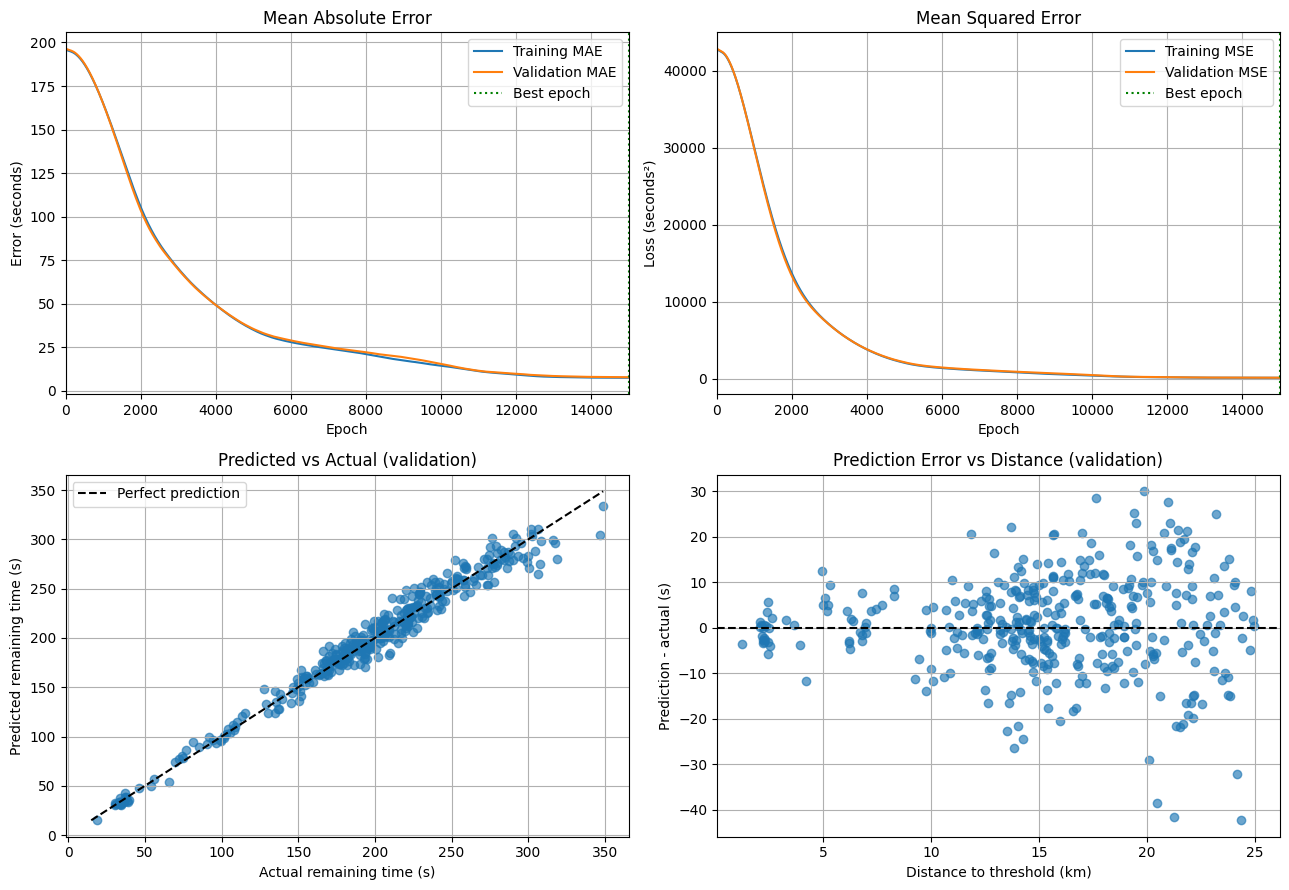

Stopped at epoch 15000/15000 (early stop: False)
Best validation epoch: 15000
Training MAE at best epoch: 7.58 s
Validation MAE at best epoch: 7.89 s
Training time: 61.2 s
Saved checkpoint: F:\MachineLearningF\airplanes-practice-machine-learning\training\2596_airplanes\03_more_airplanes_best.pt


In [ ]:
# ----- CONFIGURATION -----
max_epochs = 30000
patience = 1000
update_every = 200

train_losses, val_losses = [], []
train_maes, val_maes = [], []
best_val_mae = float("inf")
best_epoch = 0
best_state = None
epochs_without_improvement = 0

# ----- LIVE FIGURE -----
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plt.close(fig)  # Prevent an extra static copy of the figure
ax_mae, ax_mse = axes[0, 0], axes[0, 1]
ax_pred, ax_error = axes[1, 0], axes[1, 1]

line_train_mae, = ax_mae.plot([], [], label="Training MAE")
line_val_mae, = ax_mae.plot([], [], label="Validation MAE")
best_mae_line = ax_mae.axvline(0, color="green", linestyle=":", label="Best epoch")
ax_mae.set(title="Mean Absolute Error", xlabel="Epoch", ylabel="Error (seconds)")
ax_mae.legend()
ax_mae.grid(True)

line_train_mse, = ax_mse.plot([], [], label="Training MSE")
line_val_mse, = ax_mse.plot([], [], label="Validation MSE")
best_mse_line = ax_mse.axvline(0, color="green", linestyle=":", label="Best epoch")
ax_mse.set(title="Mean Squared Error", xlabel="Epoch", ylabel="Loss (seconds²)")
ax_mse.legend()
ax_mse.grid(True)

actual_val = y_val_tensor.numpy().ravel()
distance_val_km = val_df["distance_to_threshold_m"].to_numpy() / 1000.0


def update_graphs(epoch, validation_predictions):
    xs = range(1, epoch + 1)
    line_train_mae.set_data(xs, train_maes)
    line_val_mae.set_data(xs, val_maes)
    best_mae_line.set_xdata([best_epoch, best_epoch])
    line_train_mse.set_data(xs, train_losses)
    line_val_mse.set_data(xs, val_losses)
    best_mse_line.set_xdata([best_epoch, best_epoch])
    for ax in (ax_mae, ax_mse):
        ax.relim()
        ax.autoscale_view()
        ax.set_xlim(0, max(50, epoch))

    ax_pred.clear()
    ax_pred.scatter(actual_val, validation_predictions, alpha=0.65)
    limits = [min(actual_val.min(), validation_predictions.min()),
              max(actual_val.max(), validation_predictions.max())]
    ax_pred.plot(limits, limits, "k--", label="Perfect prediction")
    ax_pred.set(title="Predicted vs Actual (validation)",
                xlabel="Actual remaining time (s)", ylabel="Predicted remaining time (s)")
    ax_pred.legend()
    ax_pred.grid(True)

    ax_error.clear()
    ax_error.scatter(distance_val_km, validation_predictions - actual_val, alpha=0.65)
    ax_error.axhline(0, color="black", linestyle="--")
    ax_error.set(title="Prediction Error vs Distance (validation)",
                 xlabel="Distance to threshold (km)", ylabel="Prediction - actual (s)")
    ax_error.grid(True)

    fig.tight_layout()
    clear_output(wait=True)
    display(fig)


# ----- TRAINING -----
start_time = time.time()
for epoch in range(1, max_epochs + 1):
    model.train()
    train_prediction = model(X_train_tensor)
    loss = criterion(train_prediction, y_train_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        train_prediction = model(X_train_tensor)
        val_prediction = model(X_val_tensor)
        train_mse = criterion(train_prediction, y_train_tensor).item()
        val_mse = criterion(val_prediction, y_val_tensor).item()
        train_mae = torch.mean(torch.abs(train_prediction - y_train_tensor)).item()
        val_mae = torch.mean(torch.abs(val_prediction - y_val_tensor)).item()

    train_losses.append(train_mse)
    val_losses.append(val_mse)
    train_maes.append(train_mae)
    val_maes.append(val_mae)

    if val_mae < best_val_mae:
        best_val_mae = val_mae
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % update_every == 0:
        update_graphs(epoch, val_prediction.numpy().ravel())
        print(f"Epoch {epoch}/{max_epochs} | Train MAE: {train_mae:.2f}s | "
              f"Val MAE: {val_mae:.2f}s")
        print(f"Best: {best_val_mae:.2f}s at epoch {best_epoch} | "
              f"Patience: {epochs_without_improvement}/{patience}")
        time.sleep(0.05)

    if epochs_without_improvement >= patience:
        break

# ----- RESTORE BEST WEIGHTS -----
model.load_state_dict(best_state)
model.eval()
with torch.no_grad():
    best_train_prediction = model(X_train_tensor)
    best_val_prediction = model(X_val_tensor)
    final_train_mae = torch.mean(torch.abs(best_train_prediction - y_train_tensor)).item()
    final_val_mae = torch.mean(torch.abs(best_val_prediction - y_val_tensor)).item()

# ----- SAVE CHECKPOINT BESIDE EXPANDED DATASET -----
checkpoint_path = data_dir / "03_more_airplanes_best.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "architecture": [input_size, 8, 1],
    "feature_columns": list(input_columns),
    "target_column": target_column,
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "best_epoch": best_epoch,
    "best_val_mae_s": best_val_mae,
    "split_random_state": 42,
}, checkpoint_path)

update_graphs(epoch, best_val_prediction.numpy().ravel())
print(f"Stopped at epoch {epoch}/{max_epochs} (early stop: {epoch < max_epochs})")
print(f"Best validation epoch: {best_epoch}")
print(f"Training MAE at best epoch: {final_train_mae:.2f} s")
print(f"Validation MAE at best epoch: {final_val_mae:.2f} s")
print(f"Training time: {time.time() - start_time:.1f} s")
print("Saved checkpoint:", checkpoint_path)

## 11. Compare the network against simple ETA baselines

We need to know whether the neural network beats straightforward calculations:

1. **Original baseline:** `baseline_eta_s` (distance divided by current speed toward the threshold).
2. **Corrected baseline:** add a single mean correction learned **only from the training set**.
3. **Neural network:** restored best validation-checkpoint predictions.

Compare with **validation MAE**, not test MAE. A strong model should improve on these simple baselines.

In [11]:
actual = y_val.to_numpy()
baseline_pred = val_df["baseline_eta_s"].to_numpy()
correction = (y_train - train_df["baseline_eta_s"]).mean()
corrected_pred = baseline_pred + correction

model.eval()
with torch.no_grad():
    model_pred = model(X_val_tensor).numpy().ravel()


def mae_s(pred):
    return float(np.mean(np.abs(np.asarray(pred) - actual)))

baseline_results = pd.DataFrame({
    "Method": ["Original baseline", "Corrected baseline", "Neural network"],
    "Validation MAE (s)": [mae_s(baseline_pred), mae_s(corrected_pred), mae_s(model_pred)],
})
print(f"Mean correction from training flights: {correction:+.2f} s")
display(baseline_results.sort_values("Validation MAE (s)").reset_index(drop=True).round(2))

Mean correction from training flights: +34.28 s


,Method,Validation MAE (s)
0,Neural network,7.89
1,Corrected baseline,14.53
2,Original baseline,34.03


## 12. Analyze individual validation predictions

- **Predicted vs actual:** ideal points lie on the dashed diagonal.
- **Error vs distance:** positive error = predicted too many seconds; negative = predicted too few.
- **Worst cases:** inspect examples with the largest absolute errors.
- **Airport breakdown:** useful for this multi-airport dataset, but results for airports with few validation flights will be noisy.

The validation set can help us develop the model; keep the test set sealed until we've made our final model choice.

Validation analysis
MAE: 7.89 s
Maximum absolute error: 42.36 s
Mean signed error: +0.71 s
Within 10 seconds: 279/389


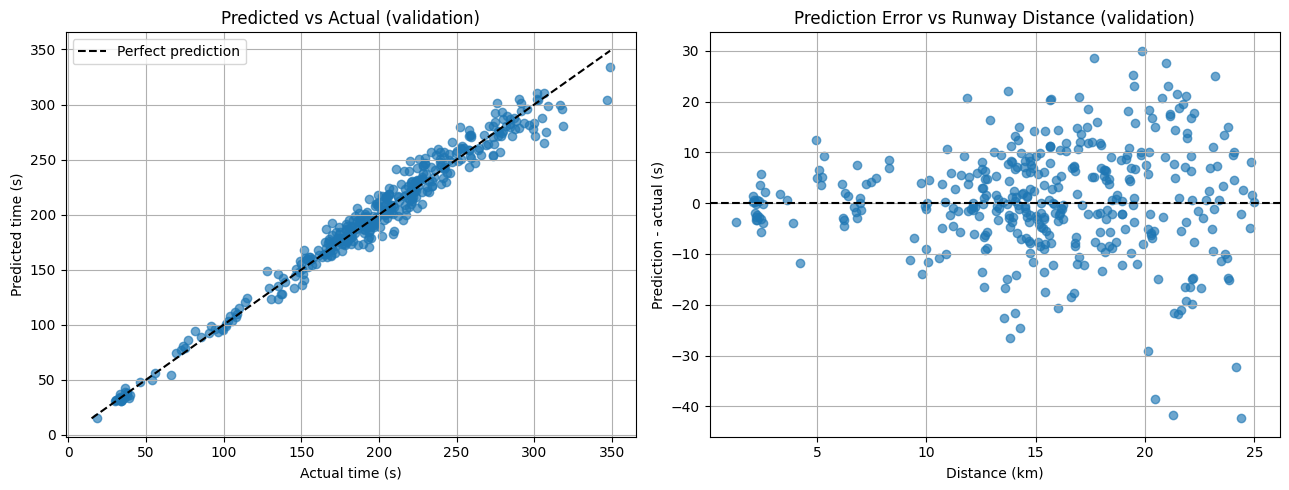


12 worst validation predictions:


,example_id,airport,runway,remaining_time_s,predicted_s,error_s,absolute_error_s,distance_to_threshold_m,groundspeed_mps,baro_altitude_m,baseline_eta_s
118,prc2024:252236144:EBBR:07R,EBBR,07R,346.79,304.420013,-42.36,42.36,24389.72,94.66,1051.56,257.93
117,prc2024:252224159:EBBR:07R,EBBR,07R,306.48,264.750000,-41.73,41.73,21262.90,92.60,579.12,229.65
352,prc2025:prc788645475:YSSY:34L,YSSY,34L,318.81,280.260010,-38.54,38.54,20474.49,74.08,647.72,276.75
157,prc2024:252275111:EBBR:25L,EBBR,25L,307.70,275.470001,-32.23,32.23,24185.77,113.18,815.34,213.73
367,prc2025:prc800078027:LHBP:31R,LHBP,31R,211.01,241.029999,30.02,30.02,19878.62,100.83,868.64,197.15
322,dorbolo20230315:484c50_20230315T184558:EHAM:18R,EHAM,18R,300.38,271.250000,-29.13,29.13,20119.20,83.85,815.34,240.30
237,prc2024:255037634:EGCC:23R,EGCC,23R,220.32,248.850006,28.53,28.53,17669.42,80.25,1021.08,220.74
46,prc2024:252120942:EBBR:25L,EBBR,25L,251.99,279.609985,27.62,27.62,20966.56,99.80,868.68,213.28
332,prc2025:prc774565033:KATL:09L,KATL,09L,209.09,182.570007,-26.52,26.52,13831.61,90.54,838.17,153.01
307,dorbolo20230315:4d24a9_20230315T080429:EHAM:18R,EHAM,18R,225.57,250.729996,25.16,25.16,19430.87,94.14,990.60,206.40



Validation MAE by airport (at least 5 validation approaches):


,approaches,mae_s
airport,,
LHBP,8,13.96
EGGD,7,13.28
EDDL,10,11.72
YSSY,10,11.72
KBOS,9,9.35
KSFO,14,8.52
LIMC,7,8.18
EDDS,19,8.13
EHAM,59,7.97



No final test evaluation performed in this notebook.


In [12]:
model.eval()
with torch.no_grad():
    predictions = model(X_val_tensor).numpy().ravel()

val_results = val_df.reset_index(drop=True).copy()
val_results["predicted_s"] = predictions
val_results["error_s"] = val_results["predicted_s"] - val_results[target_column]
val_results["absolute_error_s"] = val_results["error_s"].abs()

print("Validation analysis")
print(f"MAE: {val_results['absolute_error_s'].mean():.2f} s")
print(f"Maximum absolute error: {val_results['absolute_error_s'].max():.2f} s")
print(f"Mean signed error: {val_results['error_s'].mean():+.2f} s")
print(f"Within 10 seconds: {int((val_results['absolute_error_s'] <= 10).sum())}/{len(val_results)}")

fig, (ax_pred, ax_error) = plt.subplots(1, 2, figsize=(13, 5))
actual = val_results[target_column].to_numpy()
predicted = val_results["predicted_s"].to_numpy()
ax_pred.scatter(actual, predicted, alpha=0.65)
limits = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]
ax_pred.plot(limits, limits, "k--", label="Perfect prediction")
ax_pred.set(title="Predicted vs Actual (validation)", xlabel="Actual time (s)", ylabel="Predicted time (s)")
ax_pred.grid(True)
ax_pred.legend()

ax_error.scatter(val_results["distance_to_threshold_m"] / 1000,
                 val_results["error_s"], alpha=0.65)
ax_error.axhline(0, color="black", linestyle="--")
ax_error.set(title="Prediction Error vs Runway Distance (validation)",
             xlabel="Distance (km)", ylabel="Prediction - actual (s)")
ax_error.grid(True)
plt.tight_layout()
plt.show()

cols = ["example_id", "airport", "runway", target_column, "predicted_s", "error_s",
        "absolute_error_s", "distance_to_threshold_m", "groundspeed_mps", "baro_altitude_m",
        "baseline_eta_s"]
print("\n12 worst validation predictions:")
display(val_results.nlargest(12, "absolute_error_s")[cols].round(2))

airport_errors = val_results.groupby("airport").agg(
    approaches=("absolute_error_s", "size"),
    mae_s=("absolute_error_s", "mean"),
).sort_values("mae_s", ascending=False)
print("\nValidation MAE by airport (at least 5 validation approaches):")
display(airport_errors[airport_errors["approaches"] >= 5].round(2))

print("\nNo final test evaluation performed in this notebook.")